# 03 · Signatures — embryonic module geography -> Gate 2

Read the Gast / pSom / Crest geography off the trajectory and apply **Gate 2**. This dataset shows organized Gast<->pSom cross-repression along a single axis with Crest a terminal gradient — the **non-branching** case (GO, no bifurcation -> Gate 3 = NA). Panels show **raw** per-cell scores (the binding deliverable); smoothed scores are used only for the geography read-out.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 63/81 genes present
pSom: 66/98 genes present
Crest: 71/104 genes present
cells: 2263


## Module geography + Gate 2 logic

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
r_gp = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
crest_gast = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
crest_psom = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
crest_arm = 'Gast' if crest_gast > crest_psom else 'pSom'
print(f'\nGast<->pSom smoothed r = {r_gp:+.2f} (organized cross-repression along one axis)')
print(f'Crest co-localises with {crest_arm} pole (r_Crest,Gast={crest_gast:+.2f} vs r_Crest,pSom={crest_psom:+.2f})')
print('GATE 2: single (pSom-origin)->(Gast/Crest-terminus) axis, organized Gast/pSom cross-repression,')
print('        Crest a terminal gradient -> GO (non-branching).  FLAG: Crest enriches the GAST pole (inversion; passes anyway).')
print('GATE 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.84
  Crest_sm vs Gast_sm: r = +0.90
  Crest_sm vs pSom_sm: r = -0.84
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.865
  pSom_sm: rho = -0.708
  Crest_sm: rho = +0.949
Neural-crest-high decile mean pseudotime = 0.97 (terminal if ~1)

Gast<->pSom smoothed r = -0.84 (organized cross-repression along one axis)
Crest co-localises with Gast pole (r_Crest,Gast=+0.90 vs r_Crest,pSom=-0.84)
GATE 2: single (pSom-origin)->(Gast/Crest-terminus) axis, organized Gast/pSom cross-repression,
        Crest a terminal gradient -> GO (non-branching).  FLAG: Crest enriches the GAST pole (inversion; passes anyway).
GATE 3: no bifurcation -> NA


## Signature panels — raw per-cell scores

`(3.5,1.5)` strips on the shared house linear orientation, `plasma`, with external colorbars showing the raw score range.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


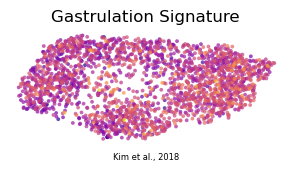

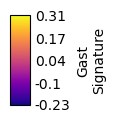

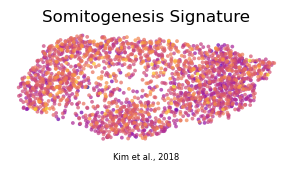

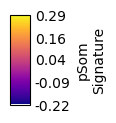

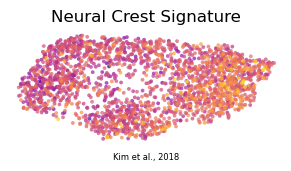

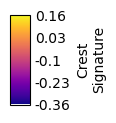

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Kim et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (2263, 12470)
